Shape after cleaning: (9994, 21)

Sales by region:
 Region
West       725457.82
East       678781.24
Central    501239.89
South      391721.90
Name: Sales, dtype: float64

Top region: West with sales 725457.82


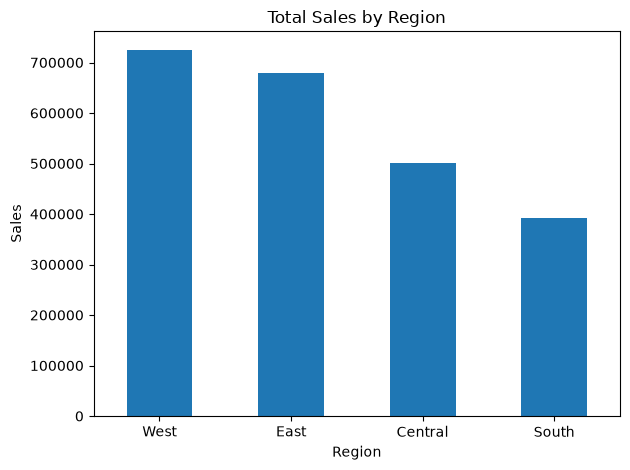

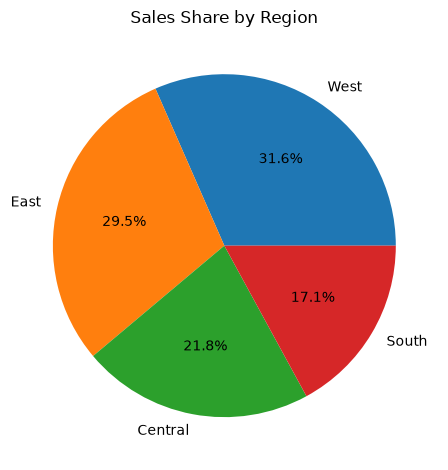


Sales by region and category:
 Category  Furniture  Office Supplies  Technology
Region                                          
Central   163797.16        167026.42   170416.31
East      208291.20        205516.06   264973.98
South     117298.68        125651.31   148771.91
West      252612.74        220853.25   251991.83


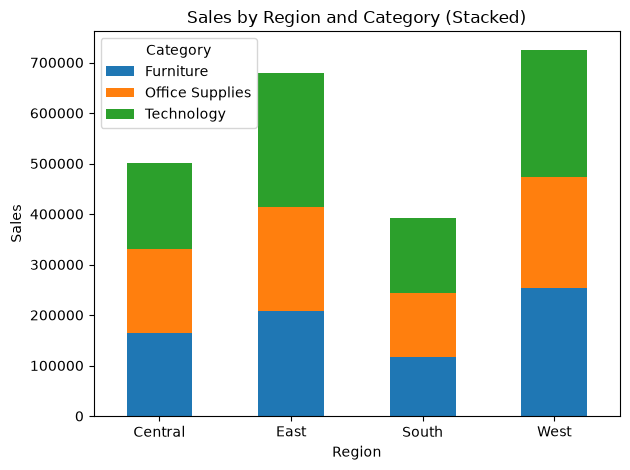

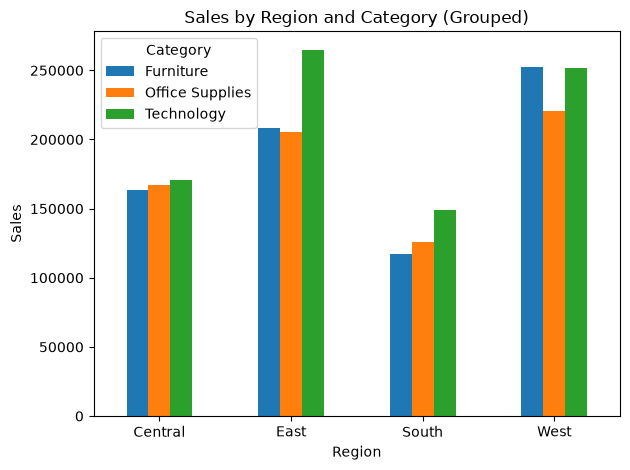

In [2]:
# Practical 12: Data Aggregation
# Aim: Aggregate retail sales by region and product category and find the
# highest-performing region.
# Dataset: Retail_Sales_Data.csv (Superstore sales)

import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("Retail_Sales_Data.csv", encoding="latin1")
df = df.drop_duplicates()
df["Sales"] = pd.to_numeric(df["Sales"], errors="coerce")
df = df.dropna(subset=["Region", "Sales", "Category"])
print("Shape after cleaning:", df.shape)

region_sales = df.groupby("Region")["Sales"].sum().sort_values(ascending=False)
print("\nSales by region:\n", region_sales.round(2))
print("\nTop region:", region_sales.idxmax(), "with sales", round(region_sales.max(), 2))

region_sales.plot(kind="bar", title="Total Sales by Region", ylabel="Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

region_sales.plot(kind="pie", autopct="%1.1f%%", ylabel="", title="Sales Share by Region")
plt.tight_layout()
plt.show()

pivot = df.pivot_table(index="Region", columns="Category", values="Sales",
                       aggfunc="sum", fill_value=0)
print("\nSales by region and category:\n", pivot.round(2))

pivot.plot(kind="bar", stacked=True, title="Sales by Region and Category (Stacked)")
plt.ylabel("Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

pivot.plot(kind="bar", title="Sales by Region and Category (Grouped)")
plt.ylabel("Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()